# Superstore Sales: Growth, Profitability and What Erodes It

This notebook is the analytical companion to the Power BI report in `powerbi/sales-report-data-modelling.pbix`.
The dashboard answers *"how much did we sell?"*; this notebook asks *"where do we actually make or lose money, and why?"*

**Dataset:** 9,994 order lines from a US office-supplies retailer (the Superstore sample dataset), 2014-2017, exported from the
Power BI data model (see `scripts/export_pbix_data.py`). Orders are joined to the Customers, Geography and Products tables
exactly as in the model's star schema.

**Questions**

1. How fast is the business growing, and is profit keeping pace with sales?
2. How seasonal is demand?
3. Which categories and sub-categories make money, and which lose it?
4. Is discounting the reason for the losses?
5. Which regions and states drive or drain profit?
6. How concentrated is revenue among customers, and how fast does the business ship?

## 1. Setup and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
BLUE, GREEN, RED, GREY = "#2b6cb0", "#2f855a", "#c53030", "#a0aec0"


def money(x, pos=None):
    """Compact dollar format: $12K, $1.2M."""
    if pd.isna(x):
        return ""
    sign = "-" if x < 0 else ""
    x = abs(x)
    if x >= 1e6:
        return f"{sign}${x / 1e6:,.2f}M"
    if x >= 1e3:
        return f"{sign}${x / 1e3:,.0f}K"
    return f"{sign}${x:,.0f}"

In [2]:
CANDIDATES = [Path("data/superstore_orders.csv"), Path("../data/superstore_orders.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("superstore_orders.csv not found - run `python scripts/export_pbix_data.py` first.")

df = pd.read_csv(DATA_PATH, parse_dates=["Order Date", "Ship Date"])
print(f"Loaded {len(df):,} order lines x {df.shape[1]} columns from {DATA_PATH}")
df.head(3)

Loaded 9,994 order lines x 17 columns from data/superstore_orders.csv


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Sales,Quantity,Discount,Profit,Segment,City,State,Postal Code,Region,Category,Sub-Category,Product Name
0,CA-2015-106320,2015-09-25,2015-09-30,Standard Class,EB-13870,1044.63,3,0.0,240.2649,Consumer,Orem,Utah,84057,West,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table
1,CA-2016-169194,2016-06-20,2016-06-25,Standard Class,LH-16900,45.00,3,0.0,4.9500,Consumer,Dover,Delaware,19901,East,Technology,Accessories,Imation 8gb Micro Traveldrive Usb 2.0 Flash Drive
2,CA-2015-135545,2015-11-24,2015-11-30,Standard Class,KM-16720,146.73,3,0.0,68.9631,Consumer,Los Angeles,California,90004,West,Office Supplies,Paper,Xerox 1943


## 2. Data-quality audit and feature engineering

In [3]:
print("Missing values per column:", int(df.isna().sum().sum()))
dups = df.duplicated()
print(f"Exact duplicate rows     : {dups.sum()}  "
      f"(Sales ${df.loc[dups, 'Sales'].sum():,.2f} = {df.loc[dups, 'Sales'].sum() / df['Sales'].sum():.4%} of total; kept so totals match the dashboard)")
print(f"Date range               : {df['Order Date'].min():%Y-%m-%d} to {df['Order Date'].max():%Y-%m-%d}")
print(f"Orders / customers       : {df['Order ID'].nunique():,} orders, {df['Customer ID'].nunique():,} customers")

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Margin"] = df["Profit"] / df["Sales"]
df["Loss Making"] = df["Profit"] < 0

assert (df["Ship Days"] >= 0).all(), "found orders that ship before they are placed"
df[["Sales", "Quantity", "Discount", "Profit", "Ship Days"]].describe().round(2)

Missing values per column: 0
Exact duplicate rows     : 1  (Sales $281.37 = 0.0122% of total; kept so totals match the dashboard)
Date range               : 2014-01-03 to 2017-12-30
Orders / customers       : 5,009 orders, 793 customers


,Sales,Quantity,Discount,Profit,Ship Days
count,9994.00,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66,3.96
std,623.25,2.23,0.21,234.26,1.75
min,0.44,1.00,0.00,-6599.98,0.00
25%,17.28,2.00,0.00,1.73,3.00
50%,54.49,3.00,0.20,8.67,4.00
75%,209.94,5.00,0.20,29.36,5.00
max,22638.48,14.00,0.80,8399.98,7.00


## 3. Headline KPIs

In [4]:
total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
kpis = pd.Series({
    "Sales": money(total_sales),
    "Profit": money(total_profit),
    "Profit margin": f"{total_profit / total_sales:.1%}",
    "Orders": f"{df['Order ID'].nunique():,}",
    "Customers": f"{df['Customer ID'].nunique():,}",
    "Avg order value": money(total_sales / df["Order ID"].nunique()),
    "Units sold": f"{df['Quantity'].sum():,}",
    "Avg discount (line level)": f"{df['Discount'].mean():.1%}",
})
kpis.to_frame("Value")

,Value
Sales,$2.30M
Profit,$286K
Profit margin,12.5%
Orders,"5,009"
Customers,793
Avg order value,$459
Units sold,"37,873"
Avg discount (line level),15.6%


## 4. Growth: is profit keeping pace with sales?

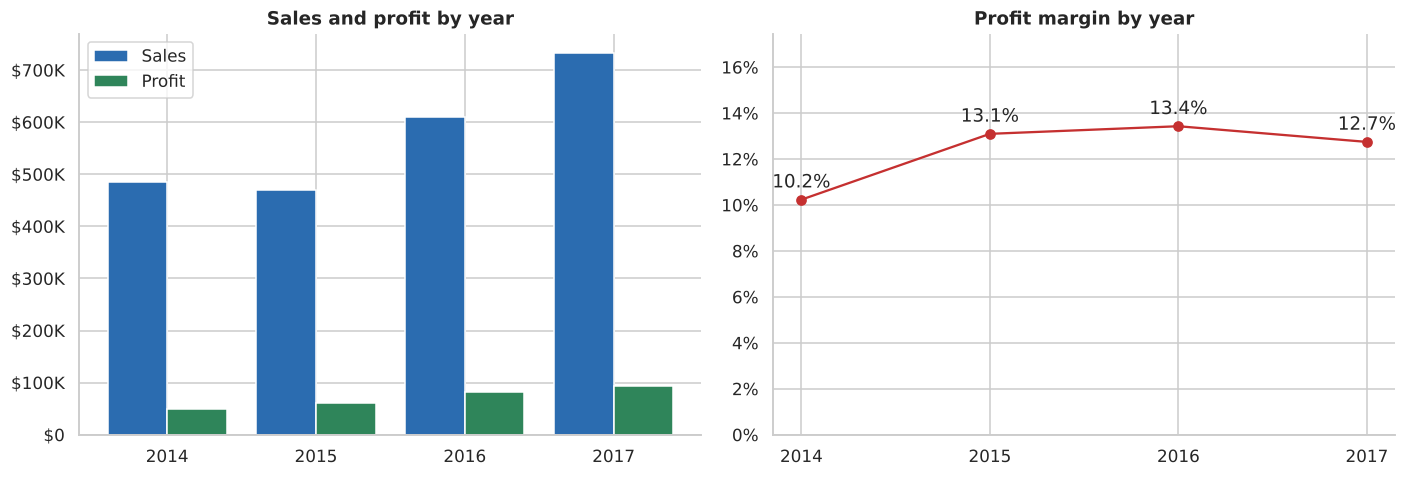

,Sales,Profit,Orders,Customers,Margin,Sales YoY,Profit YoY
Year,,,,,,,
2014,$484K,$50K,969,595,10.2%,,
2015,$471K,$62K,1038,573,13.1%,-2.8%,+24.4%
2016,$609K,$82K,1315,638,13.4%,+29.5%,+32.7%
2017,$733K,$93K,1687,693,12.7%,+20.4%,+14.2%


In [5]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                Orders=("Order ID", "nunique"), Customers=("Customer ID", "nunique"))
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
yearly["Sales YoY"] = yearly["Sales"].pct_change()
yearly["Profit YoY"] = yearly["Profit"].pct_change()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(yearly))
axes[0].bar(x - 0.2, yearly["Sales"], 0.4, color=BLUE, label="Sales")
axes[0].bar(x + 0.2, yearly["Profit"], 0.4, color=GREEN, label="Profit")
axes[0].set_xticks(x, yearly.index)
axes[0].yaxis.set_major_formatter(money)
axes[0].set_title("Sales and profit by year")
axes[0].legend()

axes[1].plot(yearly.index, yearly["Margin"], marker="o", color=RED)
for yr, m in yearly["Margin"].items():
    axes[1].annotate(f"{m:.1%}", (yr, m), textcoords="offset points", xytext=(0, 8), ha="center")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_xticks(yearly.index)
axes[1].set_ylim(0, yearly["Margin"].max() * 1.3)
axes[1].set_title("Profit margin by year")
plt.tight_layout()
plt.show()

shown = yearly.copy()
for c in ["Sales", "Profit"]:
    shown[c] = shown[c].map(money)
for c in ["Margin", "Sales YoY", "Profit YoY"]:
    shown[c] = shown[c].map(lambda v: "" if pd.isna(v) else f"{v:+.1%}" if "YoY" in c else f"{v:.1%}")
shown

## 5. Seasonality

Which months matter most? Normalising by year shows the *pattern* independent of overall growth.

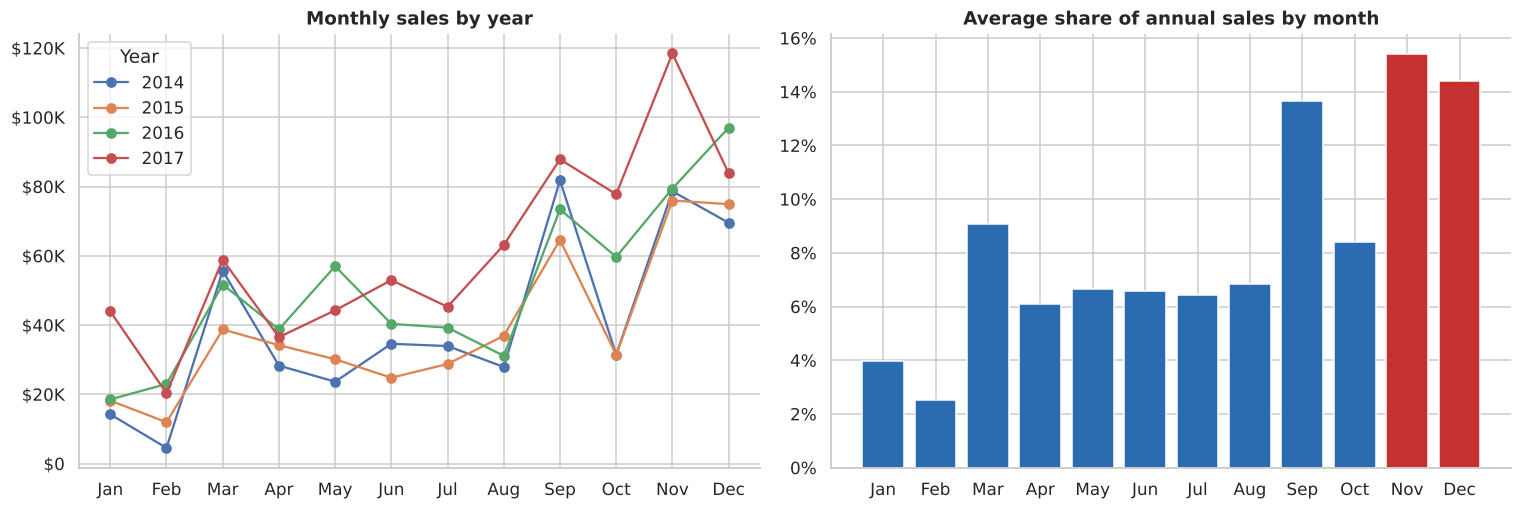

November + December average 30% of annual sales; the single strongest month is Nov (15.4%).


In [6]:
monthly = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for yr in monthly.columns:
    axes[0].plot(months, monthly[yr], marker="o", label=str(yr))
axes[0].yaxis.set_major_formatter(money)
axes[0].set_title("Monthly sales by year")
axes[0].legend(title="Year")

share = monthly.div(monthly.sum()).mean(axis=1)
axes[1].bar(months, share, color=[RED if m in ("Nov", "Dec") else BLUE for m in months])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_title("Average share of annual sales by month")
plt.tight_layout()
plt.show()

q4_share = share.loc[[11, 12]].sum()
peak_month = months[int(share.idxmax()) - 1]
print(f"November + December average {q4_share:.0%} of annual sales; the single strongest month is {peak_month} ({share.max():.1%}).")

## 6. Product profitability

A healthy total hides a lot. Margin by sub-category shows where the business earns, and where it loses money.

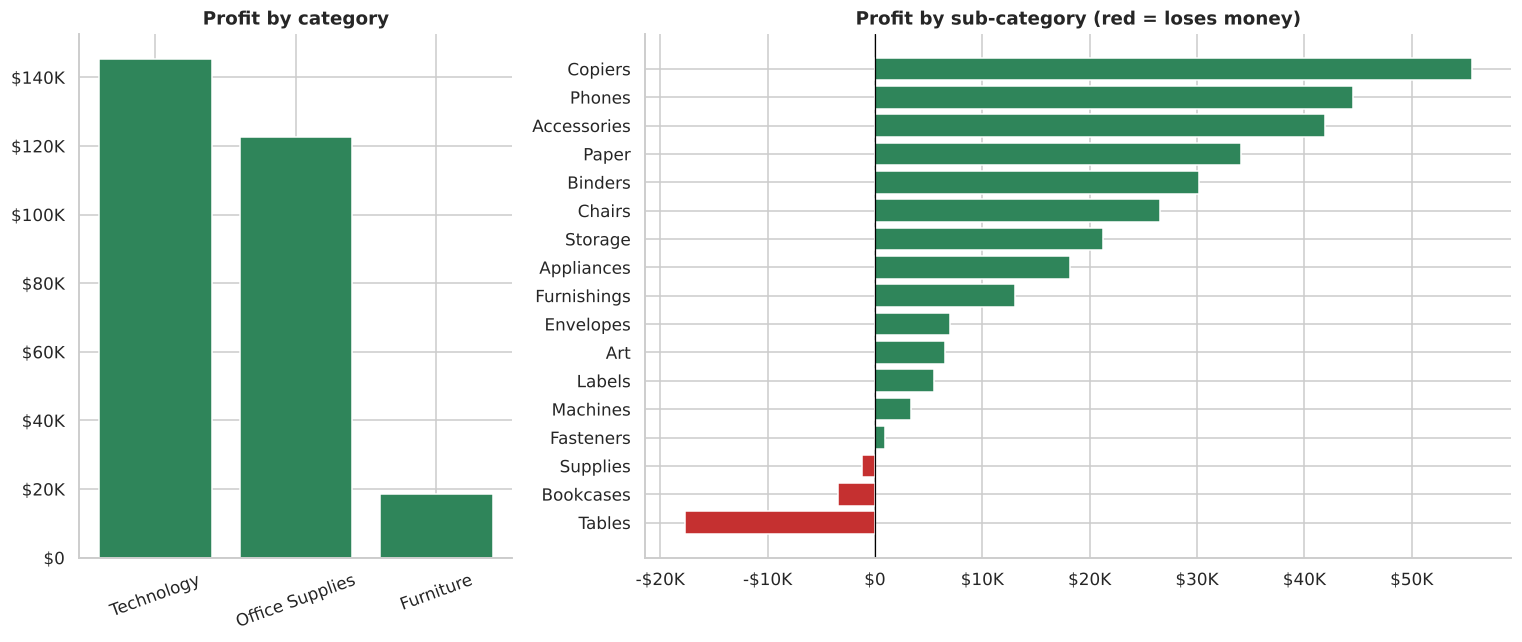

Sales Profit  Units Avg_Discount Margin
Category        Sub-Category                                         
Technology      Copiers       $150K   $56K    234          16%  37.2%
                Phones        $330K   $45K   3289          15%  13.5%
                Accessories   $167K   $42K   2976           8%  25.1%
Office Supplies Paper          $78K   $34K   5178           7%  43.4%
                Binders       $203K   $30K   5974          37%  14.9%
Furniture       Chairs        $328K   $27K   2356          17%   8.1%
Office Supplies Storage       $224K   $21K   3158           7%   9.5%
                Appliances    $108K   $18K   1729          17%  16.9%
Furniture       Furnishings    $92K   $13K   3563          14%  14.2%
Office Supplies Envelopes      $16K    $7K    906           8%  42.3%
                Art            $27K    $7K   3000           7%  24.1%
                Labels         $12K    $6K   1400           7%  44.4%
Technology      Machines      $189K    $3K    440          31%   1.8%
Office Supplies Fasteners       $3K   $950    914           8%  31.4%
                Supplies       $47K   -$1K    647           8%  -2.5%
Furniture       Bookcases     $115K   -$3K    868          21%  -3.0%
                Tables        $207K  -$18K   1241          26%  -8.6%

In [7]:
def perf(frame, by):
    g = frame.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                              Units=("Quantity", "sum"), Avg_Discount=("Discount", "mean"))
    g["Margin"] = g["Profit"] / g["Sales"]
    return g.sort_values("Profit", ascending=False)


cat = perf(df, "Category")
sub = perf(df, ["Category", "Sub-Category"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(cat.index, cat["Profit"], color=[GREEN if v > 0 else RED for v in cat["Profit"]])
axes[0].yaxis.set_major_formatter(money)
axes[0].set_title("Profit by category")
axes[0].tick_params(axis="x", rotation=20)

s = sub.reset_index().sort_values("Profit")
labels = s["Sub-Category"]
axes[1].barh(labels, s["Profit"], color=[GREEN if v > 0 else RED for v in s["Profit"]])
axes[1].xaxis.set_major_formatter(money)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Profit by sub-category (red = loses money)")
plt.tight_layout()
plt.show()

shown = sub.copy()
shown["Sales"] = shown["Sales"].map(money)
shown["Profit"] = shown["Profit"].map(money)
shown["Margin"] = shown["Margin"].map("{:.1%}".format)
shown["Avg_Discount"] = shown["Avg_Discount"].map("{:.0%}".format)
shown

## 7. Is discounting the cause?

Discount is the lever the business controls directly. Grouping order lines into discount bands shows what happens to margin as
discounts deepen.

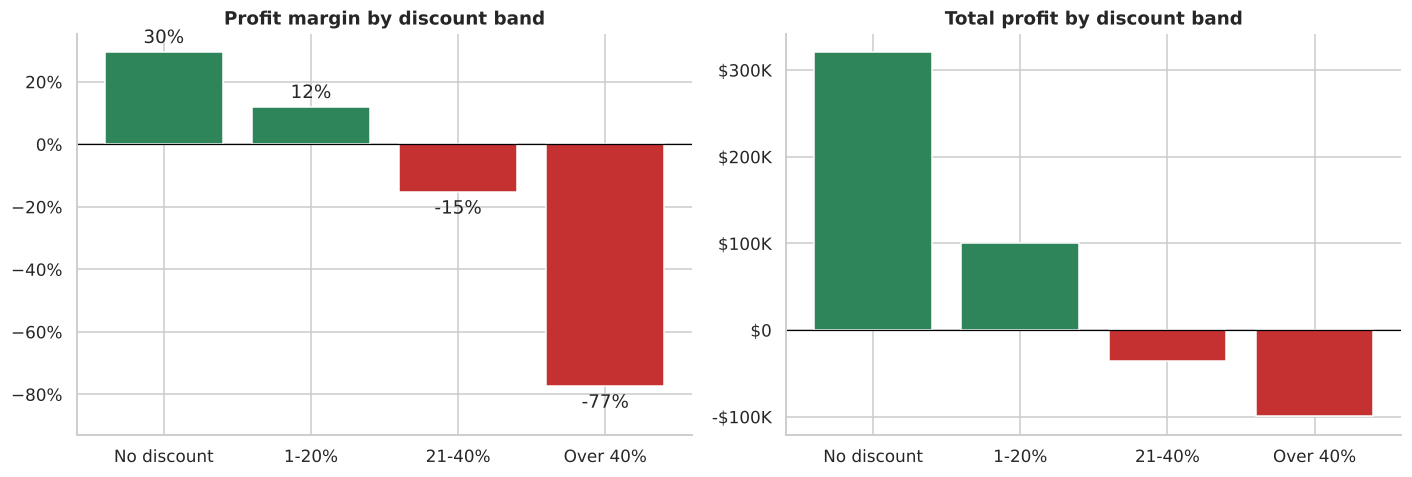

Spearman correlation, discount vs line margin: rho = -0.65 (p < 0.001)
18.7% of order lines lose money (total losses -$156K).
Lines discounted more than 20% are 13.9% of all lines but account for 89% of all losses.


In [8]:
bands = pd.cut(df["Discount"], bins=[-0.001, 0, 0.2, 0.4, 1.0], labels=["No discount", "1-20%", "21-40%", "Over 40%"])
disc = df.groupby(bands, observed=True).agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
disc["Margin"] = disc["Profit"] / disc["Sales"]
disc["Share of lines"] = disc["Lines"] / disc["Lines"].sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(disc.index.astype(str), disc["Margin"], color=[GREEN if v > 0 else RED for v in disc["Margin"]])
for i, v in enumerate(disc["Margin"]):
    axes[0].annotate(f"{v:.0%}", (i, v), textcoords="offset points", xytext=(0, 6 if v > 0 else -14), ha="center")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylim(min(disc["Margin"].min() * 1.2, -0.05), disc["Margin"].max() * 1.2)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].set_title("Profit margin by discount band")

axes[1].bar(disc.index.astype(str), disc["Profit"], color=[GREEN if v > 0 else RED for v in disc["Profit"]])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].yaxis.set_major_formatter(money)
axes[1].set_title("Total profit by discount band")
plt.tight_layout()
plt.show()

rho, p = stats.spearmanr(df["Discount"], df["Margin"])
p_txt = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
print(f"Spearman correlation, discount vs line margin: rho = {rho:+.2f} ({p_txt})")

losses = df.loc[df["Loss Making"], "Profit"]
heavy = df["Discount"] > 0.2
print(f"{df['Loss Making'].mean():.1%} of order lines lose money (total losses {money(losses.sum())}).")
print(f"Lines discounted more than 20% are {heavy.mean():.1%} of all lines but account for "
      f"{df.loc[heavy & df['Loss Making'], 'Profit'].sum() / losses.sum():.0%} of all losses.")

## 8. Geography

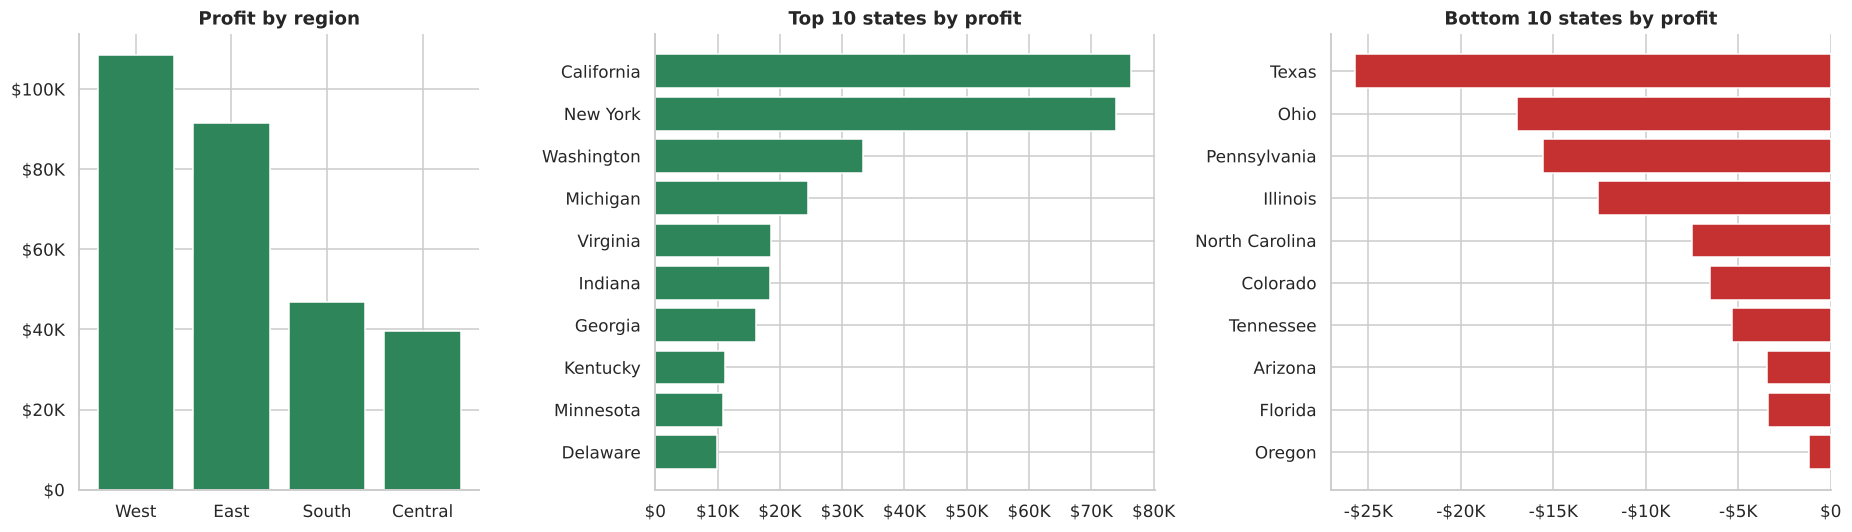

,Sales,Profit,Units,Avg_Discount,Margin
Region,,,,,
West,$725K,$108K,12266,11%,14.9%
East,$679K,$92K,10618,15%,13.5%
South,$392K,$47K,6209,15%,11.9%
Central,$501K,$40K,8780,24%,7.9%


In [9]:
region = perf(df, "Region")
state = perf(df, "State")
top = state.nlargest(10, "Profit")
bottom = state.nsmallest(10, "Profit")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [0.8, 1, 1]})
axes[0].bar(region.index, region["Profit"], color=[GREEN if v > 0 else RED for v in region["Profit"]])
axes[0].yaxis.set_major_formatter(money)
axes[0].set_title("Profit by region")
axes[1].barh(top.index[::-1], top["Profit"][::-1], color=GREEN)
axes[1].xaxis.set_major_formatter(money)
axes[1].set_title("Top 10 states by profit")
axes[2].barh(bottom.index[::-1], bottom["Profit"][::-1], color=RED)
axes[2].xaxis.set_major_formatter(money)
axes[2].set_title("Bottom 10 states by profit")
plt.tight_layout()
plt.show()

shown = region.copy()
shown["Sales"] = shown["Sales"].map(money)
shown["Profit"] = shown["Profit"].map(money)
shown["Margin"] = shown["Margin"].map("{:.1%}".format)
shown["Avg_Discount"] = shown["Avg_Discount"].map("{:.0%}".format)
shown

## 9. Customers and segments

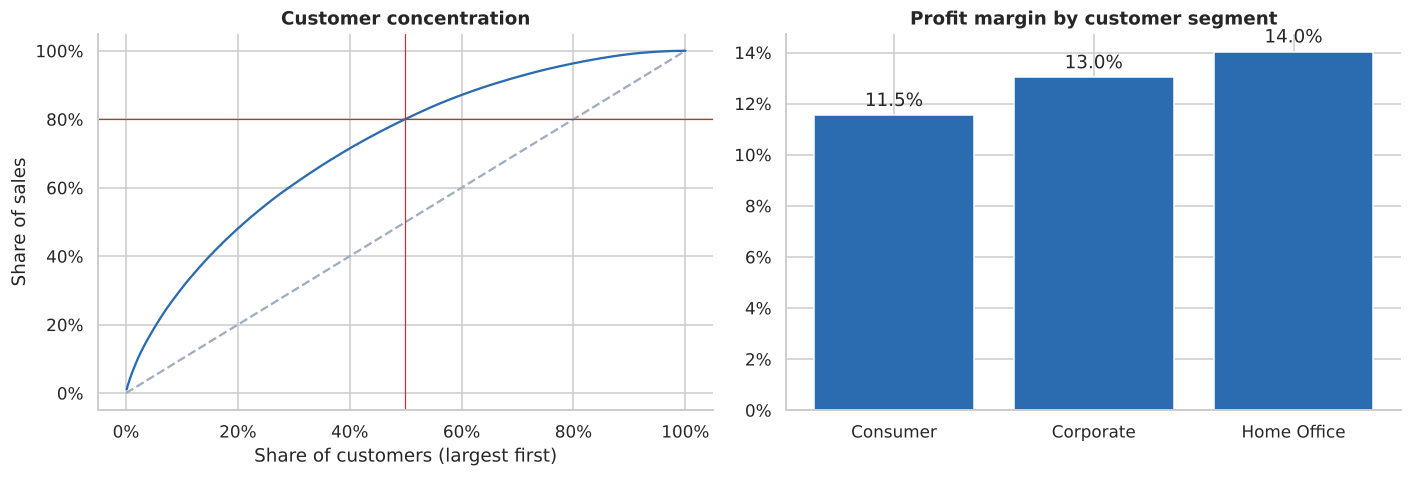

80% of sales come from 396 of 793 customers (50%).
The top 10% of customers account for 31% of sales.


In [10]:
segment = perf(df, "Segment")

cust = df.groupby("Customer ID")["Sales"].sum().sort_values(ascending=False)
cum = cust.cumsum() / cust.sum()
pct_customers = np.arange(1, len(cust) + 1) / len(cust)
n80 = int((cum < 0.8).sum()) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(pct_customers, cum.values, color=BLUE)
axes[0].plot([0, 1], [0, 1], ls="--", color=GREY)
axes[0].axhline(0.8, color=RED, lw=0.8)
axes[0].axvline(n80 / len(cust), color=RED, lw=0.8)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].set_xlabel("Share of customers (largest first)")
axes[0].set_ylabel("Share of sales")
axes[0].set_title("Customer concentration")

axes[1].bar(segment.index, segment["Margin"], color=BLUE)
for i, v in enumerate(segment["Margin"]):
    axes[1].annotate(f"{v:.1%}", (i, v), textcoords="offset points", xytext=(0, 6), ha="center")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_title("Profit margin by customer segment")
plt.tight_layout()
plt.show()

print(f"80% of sales come from {n80:,} of {len(cust):,} customers ({n80 / len(cust):.0%}).")
print(f"The top 10% of customers account for {cust.head(int(len(cust) * 0.1)).sum() / cust.sum():.0%} of sales.")

## 10. Shipping performance

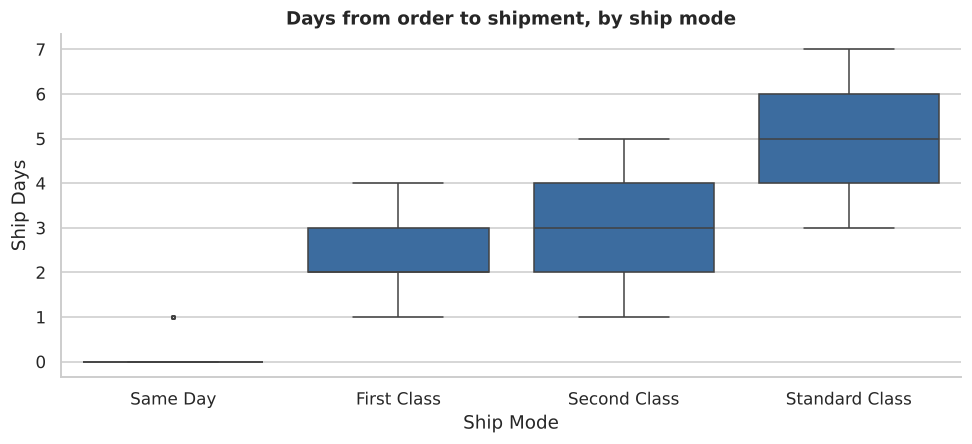

,Lines,Avg_Days,Max_Days,Margin,Share of lines
Ship Mode,,,,,
Same Day,543,0.0,1,13.8%,5%
First Class,1538,2.2,4,11.6%,15%
Second Class,1945,3.2,5,15.0%,19%
Standard Class,5968,5.0,7,11.0%,60%


In [11]:
ship = df.groupby("Ship Mode").agg(Lines=("Ship Days", "size"), Avg_Days=("Ship Days", "mean"),
                                   Max_Days=("Ship Days", "max"), Margin=("Margin", "mean"))
ship["Share of lines"] = ship["Lines"] / ship["Lines"].sum()
order = ship.sort_values("Avg_Days").index

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=df, x="Ship Mode", y="Ship Days", order=order, color=BLUE, fliersize=2, ax=ax)
ax.set_title("Days from order to shipment, by ship mode")
plt.tight_layout()
plt.show()

shown = ship.loc[order].copy()
shown["Avg_Days"] = shown["Avg_Days"].round(1)
shown["Share of lines"] = shown["Share of lines"].map("{:.0%}".format)
shown["Margin"] = shown["Margin"].map("{:.1%}".format)
shown

## 11. Key findings (computed from the data above)

In [12]:
loss_subs = sub[sub["Profit"] < 0]
best_sub = sub["Profit"].idxmax()
best_cat_margin = cat["Margin"].idxmax()
worst_state = state["Profit"].idxmin()
best_region = region["Profit"].idxmax()
worst_region = region["Profit"].idxmin()
first, last = yearly.index.min(), yearly.index.max()
cagr = (yearly.loc[last, "Sales"] / yearly.loc[first, "Sales"]) ** (1 / (last - first)) - 1

print(f"1. Growth: sales grew from {money(yearly.loc[first, 'Sales'])} ({first}) to {money(yearly.loc[last, 'Sales'])} ({last}), "
      f"a {cagr:.0%} compound annual rate; margin moved from {yearly.loc[first, 'Margin']:.1%} to {yearly.loc[last, 'Margin']:.1%}.")
print(f"2. Seasonality: Nov-Dec deliver {q4_share:.0%} of annual sales, so inventory and staffing should peak ahead of Q4.")
print(f"3. Profit pools: {best_cat_margin} has the highest margin ({cat.loc[best_cat_margin, 'Margin']:.1%}); "
      f"the single most profitable sub-category is {best_sub[1]} ({money(sub.loc[best_sub, 'Profit'])}).")
if len(loss_subs):
    names = ", ".join(f"{i[1]} ({money(r['Profit'])})" for i, r in loss_subs.iterrows())
    print(f"4. Loss-makers: {len(loss_subs)} sub-categories lose money overall: {names}.")
else:
    print("4. Loss-makers: no sub-category loses money overall.")
print(f"5. Discounting: margin is {disc.loc['No discount', 'Margin']:.1%} with no discount but {disc.loc['Over 40%', 'Margin']:.1%} on discounts "
      f"over 40%. Lines discounted more than 20% make up {heavy.mean():.0%} of lines and {df.loc[heavy & df['Loss Making'], 'Profit'].sum() / losses.sum():.0%} of losses.")
print(f"6. Geography: {best_region} is the most profitable region ({money(region.loc[best_region, 'Profit'])}); "
      f"{worst_region} the least ({money(region.loc[worst_region, 'Profit'])}). The weakest state is {worst_state} ({money(state.loc[worst_state, 'Profit'])}).")
print(f"7. Customers: 80% of sales come from {n80 / len(cust):.0%} of customers, so revenue is spread rather than dependent on a few accounts.")

1. Growth: sales grew from $484K (2014) to $733K (2017), a 15% compound annual rate; margin moved from 10.2% to 12.7%.
2. Seasonality: Nov-Dec deliver 30% of annual sales, so inventory and staffing should peak ahead of Q4.
3. Profit pools: Technology has the highest margin (17.4%); the single most profitable sub-category is Copiers ($56K).
4. Loss-makers: 3 sub-categories lose money overall: Supplies (-$1K), Bookcases (-$3K), Tables (-$18K).
5. Discounting: margin is 29.5% with no discount but -77.4% on discounts over 40%. Lines discounted more than 20% make up 14% of lines and 89% of losses.
6. Geography: West is the most profitable region ($108K); Central the least ($40K). The weakest state is Texas (-$26K).
7. Customers: 80% of sales come from 50% of customers, so revenue is spread rather than dependent on a few accounts.


## 12. Recommendations and caveats

**Recommendations** (each follows from a number above)

- **Cap discounts.** The margin collapse at high discount levels is the clearest lever; test a ceiling on discounts for the loss-making sub-categories first.
- **Review the loss-making sub-categories' pricing and sourcing** before investing further in growth there.
- **Plan capacity for Q4,** where a disproportionate share of sales lands.
- **Investigate the weakest states** for pricing, freight or discounting differences rather than treating the region as one block.

**Caveats**

- This is a **sample dataset**, so findings illustrate method and are not real business guidance.
- The relationship between discount and loss is **observational**: deeper discounts may also coincide with product mix, clearance of old stock or specific regions.
- Profit is taken as given; costs (COGS, shipping, overhead) are not available to audit.
- Four years is a short series for judging seasonality and trend.